# 🚚 **Entregables**

**No olvide duplicar esta notebook para poder editar: File->Save a copy in Drive**

En este laboratorio, no es necesario redactar un informe en un documento separado. Por favor, complete todas las actividades requeridas dentro de esta notebook de Google Colab. Recuerde que una notebook le permite ingresar elementos de texto de manera similar a un procesador de documentos. Una vez finalizadas las actividades propuestas, deberá entregar lo siguiente en la plataforma:

1. Un archivo PDF. En Google Colab puede generarlo desde el menú "Archivo" -> "Imprimir".

2. opcional: El enlace público de Google Colab. Para ello, vaya al botón de compartir y cambie la configuración de compartición a "Cualquier persona con el enlace".

3. notebook ipynb

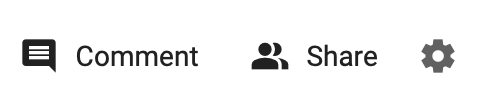

# 📔 **Resolución**
Una vez que la nota sea entregada, encontrarás la resolución en este link de notion:

https://www.notion.so/R-Churn-lab-classification-LogReg-with-and-without-GridSearchCV-154d05ccf4124959a2f7726d14dcd429?source=copy_link

Recuerda que existen varias formar de solucionar las actividades propuestas en los laboratorios. Toma la resolución entregada como referencia. En caso de que el link de resolución no esté público, solicita acceso en el mismo link de notion.|

# Predicción de pérdida de clientes en Empresas de Servicios de Telecomunicaciones (Churn)

Reducir las salidas y [deserciones de clientes](https://www.bain.com/insights/breaking-the-back-of-customer-churn/) se ha convertido en una alta prioridad para la mayoría de los proveedores de servicios de comunicaciones a medida que los mercados maduran y la competencia se intensifica.




En este documento usaremos una base de datos de una empresa de telecomunicaciones anónima [disponibilizada por IBM](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv).

El principal objetivo es crear un model de aprendizaje automático basado Regresión Logística (similar al propuesto [aquí con SVM](https://github.com/mmcuri/ds_handson/blob/master/Telecom_Churn_Prediction.ipynb)) para predecir la pérdida o salida de clientes en una empresa de telecomunicaciones.


## Librerías

Importamos varias bibliotecas y módulos útiles para el análisis de datos y el aprendizaje automático en Python. A continuación se describe cada uno de ellos:

- `pandas as pd`: Importa la biblioteca Pandas y la renombra como "pd". Pandas es una biblioteca popular utilizada para la manipulación y análisis de datos en Python.

- `numpy as np`: Importa la biblioteca NumPy y la renombra como "np". NumPy es una biblioteca de Python utilizada para realizar operaciones matemáticas en matrices y vectores.

- `matplotlib.pyplot as plt`: Importa la biblioteca Matplotlib y el módulo pyplot y lo renombra como "plt". Matplotlib es una biblioteca utilizada para la visualización de datos en Python.

- `from sklearn.metrics import classification_report`: Importa la función classification_report desde el módulo metrics de la biblioteca scikit-learn. classification_report es una función que calcula y muestra un informe de clasificación detallado para un modelo de clasificación.

- `from sklearn.metrics import confusion_matrix`: Importa la función confusion_matrix desde el módulo metrics de la biblioteca scikit-learn. confusion_matrix es una función que calcula y muestra la matriz de confusión para un modelo de clasificación.

- `from sklearn.metrics import accuracy_score`: Importa la función accuracy_score desde el módulo metrics de la biblioteca scikit-learn. accuracy_score es una función que calcula y muestra la precisión de un modelo de clasificación.

- `from sklearn.metrics import roc_auc_score`: Importa la función roc_auc_score desde el módulo metrics de la biblioteca scikit-learn. roc_auc_score es una función que calcula el área bajo la curva ROC (AUC) para un modelo de clasificación.

- `from sklearn.preprocessing import StandardScaler, LabelEncoder`: Importa las clases StandardScaler y LabelEncoder desde el módulo preprocessing de la biblioteca scikit-learn. StandardScaler es una clase utilizada para estandarizar los datos y LabelEncoder es una clase utilizada para codificar las etiquetas de clase en números enteros.

- `from sklearn.model_selection import train_test_split`: Importa la función train_test_split desde el módulo model_selection de la biblioteca scikit-learn. train_test_split es una función que divide los datos en conjuntos de entrenamiento y prueba para su uso en el modelado predictivo.

En resumen, este código importa varias bibliotecas y módulos que son útiles para el análisis de datos y el aprendizaje automático en Python.


In [1]:
# importing libraries
import pandas as pd #excel sofisticado
import numpy as np #matlab
import matplotlib.pyplot as plt #plots
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split


## Base de datos

Este conjunto de datos contiene un total de 7043 clientes y 21 características de los mismos. De las entradas, 5174 son clientes activos y 1869 son clientes que la empresa ha perdido. Observe que el conjunto de datos está desbalanceado pues por cada cliente perdido existe casi 3 clientes activos. La variable de salida para nuestro modelo de machine learning será `Churn`.

In [2]:
# importamos dataset
DATA_PATH = "https://raw.githubusercontent.com/mtgca/datasets_public/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
#print(df)
# vemos las primeras 5 filas
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### *Detalles de la base de datos*

*	`customerID` - Custumer unique identifier
*	`gender` - Customer gender - ['Female' 'Male']
*	`SeniorCitizen` - Elderly or retired person, a senior citizen is someone who has at least attained the age of 60 of 65 years
*	`Partner` - - ['No' 'Yes']
*	`Dependents` - If customer has dependents - ['No' 'Yes']
*	`Tenure` - Customer lifespan (in months)
*	`PhoneService` - - ['No' 'Yes']
*	`MultipleLines` - - ['No' 'No phone service' 'Yes']
*	`InternetService` - - ['No' 'No internet service' 'Yes']
*	`OnlineSecurity` - - ['No' 'No internet service' 'Yes']
*	`OnlineBackup` - - ['No' 'No internet service' 'Yes']
*	`DeviceProtection` - - ['No' 'No internet service' 'Yes']
*	`TechSupport` - - ['No' 'No internet service' 'Yes']
*	`StreamingTV` - - ['No' 'No internet service' 'Yes']
*	`StreamingMovies` -  - ['No' 'No internet service' 'Yes']
*	`Contract` - Type of contract - ['Month-to-month' 'One year' 'Two year']
*	`PaperlessBilling` - - ['No' 'Yes']
*	`PaymentMethod` - payment method - ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
*	`MonthlyCharges` - Monthly Recurring Charges
*	`TotalCharges` - Life time value
*	`Churn` - Churn value, the targer vector - ['No' 'Yes']





### *Limpieza del Dataset*

El código presenta una serie de operaciones de preprocesamiento de datos en una base de datos que contiene información sobre clientes de una compañía, incluyendo su género, edad, servicios contratados, pagos realizados, entre otros.

En primer lugar, se define la función get_df_size para imprimir el número de atributos y entradas de la base de datos.

Luego, se reemplazan los valores en blanco por NaN para facilitar el manejo de valores faltantes en la base de datos.

A continuación, se reemplazan los valores faltantes en la columna 'TotalCharges' por la mediana de esa columna y se convierte esa columna al tipo numérico.

Después, se elimina la columna 'customerID' ya que no es una característica relevante.

A continuación, se codifican las características binarias en 0's y 1's usando LabelEncoder y se imprimen las categorías correspondientes a cada una de estas características.



**¿Por qué One-Hot Encoding?**

Cuando tenemos variables categóricas (por ejemplo, Color = {Rojo, Verde, Azul}), necesitamos convertirlas en valores numéricos para que los modelos puedan procesarlas. Hay dos enfoques comunes:

1. Label Encoding:
Asigna un número entero a cada categoría

(Rojo = 0, Verde = 1, Azul = 2).

El problema es que el modelo interpreta estos valores como si hubiera una relación de orden —por ejemplo, que Azul > Verde > Rojo—, algo que no tiene sentido en variables nominales. Esto introduce una falsa relación ordinal entre categorías.

2. One-Hot Encoding:
Crea una columna binaria para cada categoría. Por ejemplo:

Rojo → (1, 0, 0), Verde → (0, 1, 0), Azul → (0, 0, 1).

Así, cada categoría se representa como un vector independiente, sin orden ni jerarquía.

En la figura:

* A la izquierda (Label Encoding), las categorías están sobre una línea, implicando un orden.

* A la derecha (One-Hot Encoding), cada categoría ocupa un eje distinto, mostrando independencia.

👉 Implicación:
El one-hot encoding evita que el modelo asuma relaciones inexistentes y garantiza un tratamiento justo entre categorías puramente nominales.

⚠️ Desventajas del One-Hot Encoding:
* Incrementa la dimensionalidad del dataset (una columna por categoría).
* Puede generar matrices muy dispersas (muchos ceros).
* Es menos eficiente para variables con muchas categorías (“high cardinality”).
* Puede aumentar el tiempo de entrenamiento y el uso de memoria en modelos grandes.

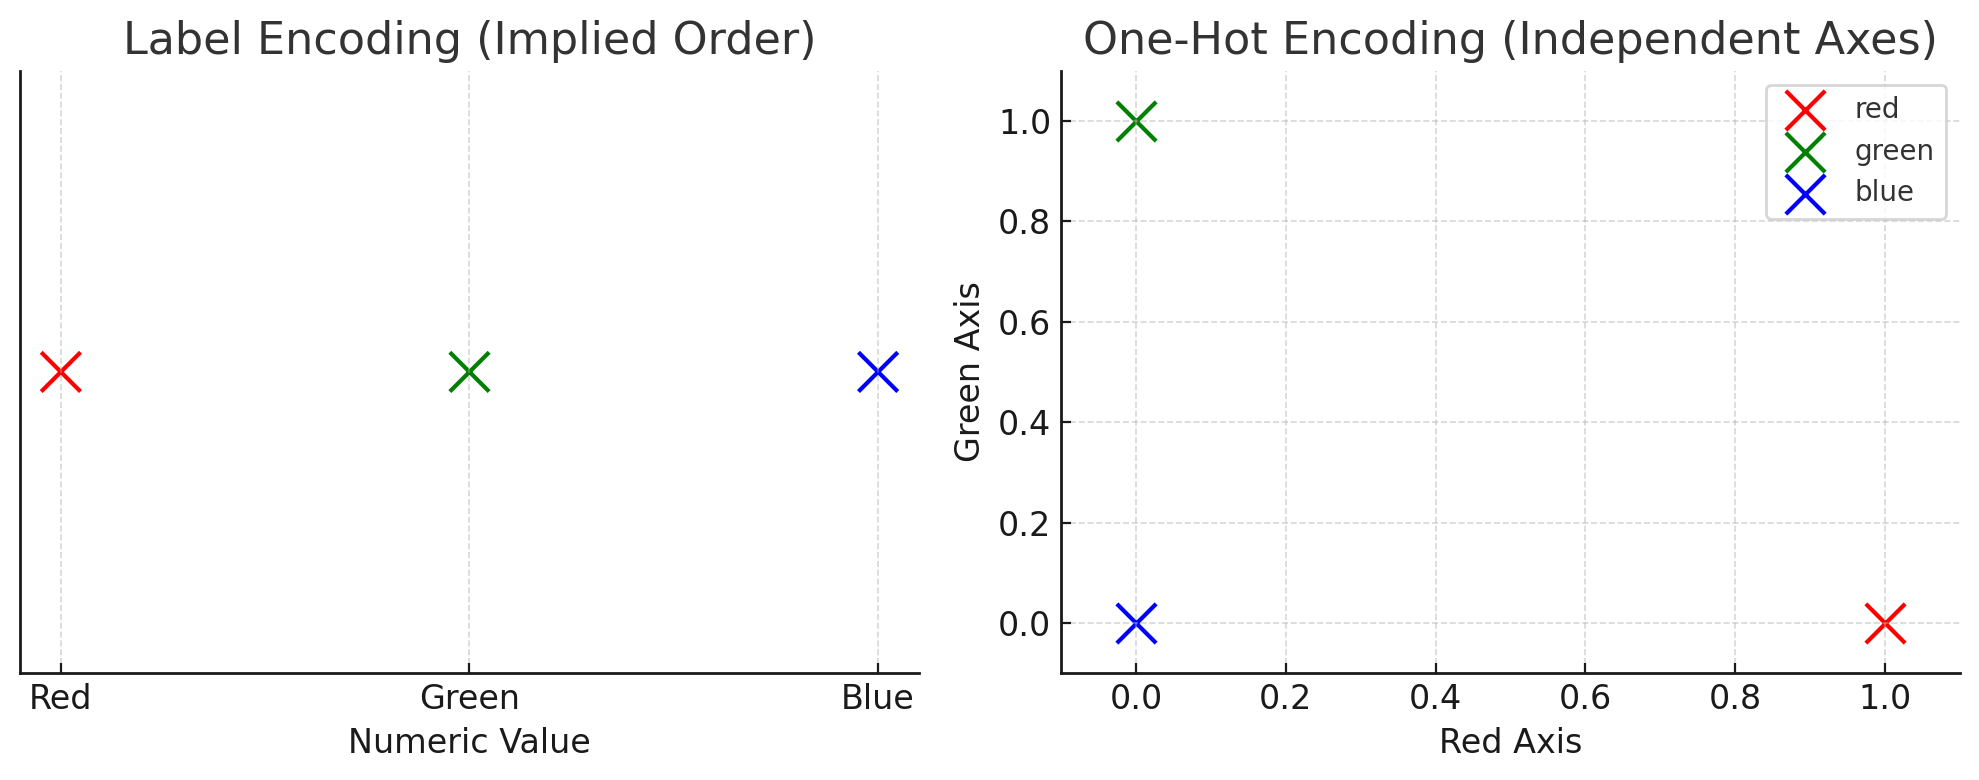

In [6]:
def get_df_size(df, header='Dataset dimensions'):
  print(header,
        '\n# Attributes: ', df.shape[1],
        '\n# Entries: ', df.shape[0],'\n')

get_df_size(df)

#df.info()

# reemplaza valores en blanco por NaN
df_clean = df.replace(r'^\s*$', np.nan, regex=True)

# Convert 'TotalCharges' to numeric before calculating the median.
# errors='coerce' will handle any non-numeric values by setting them to NaN.
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# reemplaza valores faltantes en TotalCharges por la mediana de TotalCharges.
total_charges_median = df_clean.TotalCharges.median()
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(
    total_charges_median
)
df_clean['TotalCharges'] = df_clean['TotalCharges'].apply(pd.to_numeric)

#CustomerID lo retiramos porque no es una característica
df_clean = df_clean.drop('customerID', axis=1)
df_clean.describe()

print("Churn No Instances: ", df_clean[df_clean['Churn'] == 'No'].shape[0])
print("Churn Yes Instances: ", df_clean[df_clean['Churn'] == 'Yes'].shape[0])

binary_feat = df_clean.nunique()[df_clean.nunique() == 2].keys().tolist()
numeric_feat = [col for col in df_clean.select_dtypes(['float','int']).columns.tolist() if col not in binary_feat]
categorical_feat = [
    col
    for col in df_clean.select_dtypes(
        include=["object", "str", "category"]
    ).columns
    if col not in binary_feat + numeric_feat
]
df_proc = df_clean.copy()
#Etiquetas para características binarias
le = LabelEncoder()
for i in binary_feat:
  df_proc[i] = le.fit_transform(df_proc[i])
  print(i, '\n', np.unique(df_proc[i].values))
#Dummy variables
df_proc = pd.get_dummies(df_proc, columns=categorical_feat, dtype=int)
get_df_size(df, header='Original dataset:')
get_df_size(df_proc, header='Processed dataset:')
df_proc.head()


Dataset dimensions 
# Attributes:  21 
# Entries:  7043 

Churn No Instances:  5174
Churn Yes Instances:  1869
gender 
 [0 1]
SeniorCitizen 
 [0 1]
Partner 
 [0 1]
Dependents 
 [0 1]
PhoneService 
 [0 1]
PaperlessBilling 
 [0 1]
Churn 
 [0 1]
Original dataset: 
# Attributes:  21 
# Entries:  7043 

Processed dataset: 
# Attributes:  41 
# Entries:  7043 



,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,1,0,0,0,0,1,0


### *División en conjunto de entrenamiento y test*

En el código, se divide el conjunto de datos df_proc en características y variable objetivo X e y, respectivamente. Luego, se realiza una división de los datos en conjuntos de entrenamiento y prueba utilizando la función train_test_split de scikit-learn. Los conjuntos de entrenamiento y prueba se almacenan en X_train, X_test, y_train y y_test. La división se realiza de manera estratificada para asegurar que la proporción de instancias positivas y negativas en la variable objetivo se mantenga en ambos conjuntos. Se utiliza una proporción de 80/20 para los conjuntos de entrenamiento y prueba, respectivamente, y se fija una semilla aleatoria (random_state) en 42 para asegurar que los resultados sean reproducibles.

In [7]:
# dividimos df_proc en características y salida
X=df_proc.drop('Churn', axis=1)
y=df_proc['Churn']

# Dividimos el conjunto de entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

### *Balanceo de datos*

Este código realiza el submuestreo (undersampling) de un conjunto de datos desbalanceado en términos de la variable objetivo. El submuestreo se utiliza para abordar el problema del desequilibrio de clases en el conjunto de datos, donde una o varias clases tienen muchas menos observaciones que las otras clases. En este caso, el modelo de aprendizaje automático puede estar sesgado hacia la clase mayoritaria, lo que puede resultar en un rendimiento deficiente en la clasificación de la clase minoritaria.

El submuestreo implica reducir el número de observaciones en la clase mayoritaria para equilibrar la distribución de las clases en el conjunto de datos. Esto puede mejorar el rendimiento del modelo en la clasificación de la clase minoritaria y reducir el sesgo hacia la clase mayoritaria.

La biblioteca imblearn se utiliza para realizar el submuestreo, y en este caso se importa la clase RandomUnderSampler. El objeto RandomUnderSampler se inicializa con random_state=1, lo que garantiza que los resultados serán reproducibles.

Luego, el submuestreo se realiza en el conjunto de entrenamiento (X_train, y_train) mediante el método fit_resample del objeto rus. Los datos submuestreados se almacenan en X_train_rus y y_train_rus.

Para evaluar el efecto del submuestreo, se utiliza la función get_df_size, que devuelve el tamaño del conjunto de datos. Primero se imprime el tamaño del conjunto de entrenamiento original (X_train, y_train) antes del submuestreo, y luego se imprime el tamaño del conjunto submuestreado (X_train_rus, y_train_rus) después de aplicar el submuestreo.

Finalmente, se utiliza la función np.unique para verificar que las categorías de la variable objetivo (y_train_rus) estén balanceadas. La función devuelve una tupla que contiene las categorías únicas y el número de instancias en cada categoría. Al utilizar return_counts=True, se garantiza que se devuelvan los recuentos de las categorías.

In [8]:
# submuestreo -> under sampling
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=1)
X_train_undersampled, y_train_undersampled = rus.fit_resample(X_train, y_train)
get_df_size(X_train, header='Before balancing:')
get_df_size(X_train_undersampled, header='After balancing:')

# verificamos que las categorias estén balanceadas
np.unique(y_train_undersampled, return_counts=True)


Before balancing: 
# Attributes:  40 
# Entries:  5634 

After balancing: 
# Attributes:  40 
# Entries:  2990 



(array([0, 1]), array([1495, 1495]))

## Modelo de Machine Learning

Este código construye un modelo de regresión logística para un conjunto de datos y lo evalúa en un conjunto de datos de prueba y de entrenamiento.

Primero, se define una tubería (pipeline) que encadena tres pasos:

PolynomialFeatures(degree=2): Crea una matriz de características polinómicas de grado 2 a partir de las características originales.
StandardScaler(): Estandariza las características.
LogisticRegression(max_iter=20000, penalty='l2', C=1/lambda_value): Ajusta un modelo de regresión logística a los datos, utilizando una regularización L2 (Ridge) y un parámetro de regularización C inversamente proporcional a lambda_value.
Luego, el modelo se entrena en un conjunto de datos de entrenamiento (X_train_undersampled e y_train_undersampled) utilizando el método fit.

A continuación, el modelo se evalúa en un conjunto de datos de prueba (X_test e y_test). Las predicciones se obtienen con el método predict y se calcula la precisión (accuracy) utilizando metrics.accuracy_score. La precisión en el conjunto de datos de prueba se almacena en la variable acc_test y se imprime en pantalla.

Finalmente, se evalúa el modelo en el conjunto de datos de entrenamiento (X_train_undersampled e y_train_undersampled) y se almacena la precisión en la variable acc_train, que también se imprime en pantalla.

## ✅ Actividad 1

El objetivo de esta actividad es generar un gráfico donde el eje X represente el hiperparámetro de regularización lambda (`lambda_value`) y el eje Y muestre el **recall**. El recall es una métrica entre 0 y 1, donde 1 indica el mejor rendimiento (0% falsos negativos).

El gráfico deberá incluir el recall tanto para el conjunto de entrenamiento como para el conjunto de validación. Utilice los siguientes valores de lambda para el eje X: `[1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100, 1e3, 1e4]`. Configure el eje X con una escala logarítmica para una mejor visualización.

A partir del gráfico, identifique el valor óptimo de lambda. Para ello, utilice GridSearchCV con k=5 folds.

Finalmente, evalúe el modelo optimizado (es decir, aquel con el `lambda_value` que mostró el mejor rendimiento en el conjunto de validación) en el conjunto de prueba, reportando tanto el accuracy como el recall. Tenga en cuenta que esta actividad podría **tardar en ejecutarse**.

¿Por qué considera que el recall es una métrica más adecuada para este problema? Analice la importancia de reducir los falsos negativos en la predicción de churn.


### **Opcional: Optimización Bayesiana  Optimización Bayesiana de Hiperparámetros**

La optimización bayesiana de hiperparámetros es un método avanzado para seleccionar los mejores hiperparámetros para un modelo de aprendizaje automático. A diferencia de la búsqueda en cuadrícula (**Grid Search**) y la búsqueda aleatoria (**Random Search**), que evalúan combinaciones de hiperparámetros sin considerar los resultados previos, la optimización bayesiana utiliza la información obtenida en iteraciones anteriores para decidir qué configuraciones explorar posteriormente.

Este enfoque construye un modelo probabilístico de la función objetivo (por ejemplo, la precisión de validación) y emplea dicho modelo para estimar qué regiones del espacio de búsqueda tienen mayor probabilidad de contener mejores soluciones. De esta manera, se reduce significativamente el número de evaluaciones necesarias para encontrar configuraciones de alto desempeño.

Las principales ventajas de la optimización bayesiana incluyen:

* Mayor eficiencia, al requerir menos evaluaciones que Grid Search o Random Search.
* Mejor desempeño, al concentrar la búsqueda en regiones prometedoras del espacio de hiperparámetros.
* Flexibilidad, permitiendo optimizar espacios de búsqueda complejos con variables continuas, discretas y categóricas.

**Herramientas recomendadas**

Existen varias bibliotecas para realizar optimización bayesiana en Python:

* **scikit-optimize (skopt)**: biblioteca integrada con el ecosistema de scikit-learn que proporciona la clase BayesSearchCV, similar a GridSearchCV y RandomizedSearchCV.
* **Optuna**: framework moderno para optimización automática de hiperparámetros. Utiliza por defecto el algoritmo TPE (Tree-structured Parzen Estimator), un método de optimización bayesiana eficiente para espacios de búsqueda complejos. Optuna es ampliamente utilizado tanto en investigación como en aplicaciones industriales debido a su facilidad de uso y capacidad para realizar pruning (detención temprana de experimentos poco prometedores).

**Recursos**

* Optuna: https://optuna.org/
* Scikit-Optimize: https://scikit-optimize.github.io/
* Tutorial de Scikit-Optimize: https://machinelearningmastery.com/scikit-optimize-for-hyperparameter-tuning-in-machine-learning/



In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
import sklearn.metrics as metrics

lambda_value = 1
model_logreg =  Pipeline([
                ('polynomial_features', PolynomialFeatures(degree=2)), #no cambiar
                ('scaler', StandardScaler()),
                ('logistic_regression', LogisticRegression(max_iter=20000, l1_ratio=0, C=1/lambda_value))
 ])

# training
model_logreg.fit(X_train_undersampled, y_train_undersampled)

# evaluation on test set
pred_test = model_logreg.predict(X_test)
acc_test = metrics.accuracy_score(y_test, pred_test)
print("Accuracy on test set Logistic Regression: ", acc_test)
# evaluation on training set
pred_train = model_logreg.predict(X_train_undersampled)
acc_train = metrics.accuracy_score(y_train_undersampled, pred_train)
print("Accuracy on training set Logistic Regression: ", acc_train)

Accuracy on test set Logistic Regression:  0.7338537970191625
Accuracy on training set Logistic Regression:  0.7959866220735786


Fitting 5 folds for each of 9 candidates, totalling 45 fits


,lambda,C,recall_train,recall_validacion,std_train,std_validacion
0,0.0001,10000.0000,0.824415,0.759866,0.004456,0.013277
1,0.0010,1000.0000,0.823579,0.754515,0.004487,0.014746
2,0.0100,100.0000,0.822742,0.757191,0.005419,0.014746
3,0.1000,10.0000,0.821906,0.763880,0.005912,0.016330
4,1.0000,1.0000,0.818562,0.766555,0.006584,0.014095
5,10.0000,0.1000,0.814548,0.767224,0.007161,0.011113
6,100.0000,0.0100,0.809699,0.773244,0.006511,0.005351
7,1000.0000,0.0010,0.801672,0.781271,0.003319,0.004537
8,10000.0000,0.0001,0.811204,0.806020,0.003864,0.007914


Mejor lambda entre los evaluados: 10000
C correspondiente: 0.0001
Recall medio de validación: 0.8060


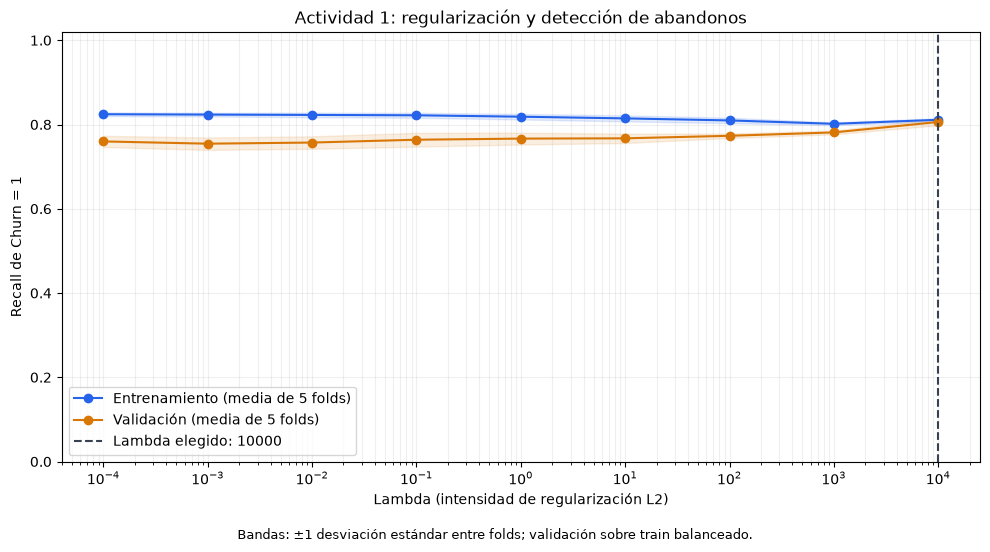

Accuracy en test: 0.7317 (73.17%)
Recall en test: 0.7968 (79.68%)
Abandonos detectados: 298 de 374
Falsos negativos (abandonos no detectados): 76
Falsos positivos (alertas sobre clientes que permanecen): 302


,Predice: permanece (0),Predice: abandona (1)
Real: permanece (0),733,302
Real: abandona (1),76,298


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from joblib import parallel_backend
from threadpoolctl import threadpool_limits
from IPython.display import display

# 1. Los nueve valores de lambda pedidos por la actividad.
lambdas = np.array([1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100, 1e3, 1e4])

# 2. GridSearchCV crea un modelo nuevo para cada combinación y cada fold.
# El escalador se ajusta solamente con los cuatro folds de entrenamiento.
pipeline_act1 = Pipeline([
    ('polynomial_features', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(
        solver='lbfgs', max_iter=20000, l1_ratio=0
    ))
])

# El doble guion bajo indica: paso del pipeline __ parámetro de ese paso.
param_grid = {'logistic_regression__C': 1 / lambdas}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_act1 = GridSearchCV(
    estimator=pipeline_act1,
    param_grid=param_grid,
    scoring='recall',                # Recall de Churn=1 (abandono).
    cv=cv,
    return_train_score=True,         # Necesario para la curva de entrenamiento.
    refit=True,                     # Reajusta el ganador con todo el train balanceado.
    n_jobs=2,
    error_score='raise',
    verbose=1
)

# 3. Usamos el train ya balanceado del laboratorio. El test queda fuera del grid.
# Dos ajustes simultáneos, limitando los hilos numéricos para no saturar el Mac.
with parallel_backend('threading'), threadpool_limits(limits=1):
    grid_act1.fit(X_train_undersampled, y_train_undersampled)

# 4. Cada punto es el promedio de los cinco folds.
# Dentro de cv_results_, "test_score" significa VALIDACIÓN del fold, no X_test.
cv_resultados = grid_act1.cv_results_
resultados_act1 = pd.DataFrame({
    'lambda': [1 / p['logistic_regression__C'] for p in cv_resultados['params']],
    'C': [p['logistic_regression__C'] for p in cv_resultados['params']],
    'recall_train': cv_resultados['mean_train_score'],
    'recall_validacion': cv_resultados['mean_test_score'],
    'std_train': cv_resultados['std_train_score'],
    'std_validacion': cv_resultados['std_test_score']
}).sort_values('lambda').reset_index(drop=True)
display(resultados_act1.round(6))

mejor_C_act1 = grid_act1.best_params_['logistic_regression__C']
mejor_lambda_act1 = 1 / mejor_C_act1
mejor_modelo_act1 = grid_act1.best_estimator_
print(f'Mejor lambda entre los evaluados: {mejor_lambda_act1:g}')
print(f'C correspondiente: {mejor_C_act1:g}')
print(f'Recall medio de validación: {grid_act1.best_score_:.4f}')

# 5. Gráfico solicitado: lambda en escala logarítmica y recall entre 0 y 1.
fig, ax = plt.subplots(figsize=(10, 5.5))
for columna, desviacion, etiqueta, color in [
    ('recall_train', 'std_train', 'Entrenamiento (media de 5 folds)', '#2563eb'),
    ('recall_validacion', 'std_validacion', 'Validación (media de 5 folds)', '#d97706')
]:
    media = resultados_act1[columna].to_numpy()
    std = resultados_act1[desviacion].to_numpy()
    ax.plot(resultados_act1['lambda'], media, marker='o', label=etiqueta, color=color)
    ax.fill_between(
        resultados_act1['lambda'],
        np.clip(media - std, 0, 1), np.clip(media + std, 0, 1),
        color=color, alpha=0.12
    )
ax.axvline(mejor_lambda_act1, color='#374151', linestyle='--',
           label=f'Lambda elegido: {mejor_lambda_act1:g}')
ax.set_xscale('log')
ax.set_xlabel('Lambda (intensidad de regularización L2)')
ax.set_ylabel('Recall de Churn = 1')
ax.set_ylim(0, 1.02)
ax.set_title('Actividad 1: regularización y detección de abandonos')
ax.grid(True, which='both', alpha=0.2)
ax.legend(loc='lower left')
fig.text(0.5, 0.01, 'Bandas: ±1 desviación estándar entre folds; validación sobre train balanceado.',
         ha='center', fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

# 6. Evaluación final: el ganador ya fue reajustado por refit=True.
# X_test / y_test mantienen la distribución original y no eligen lambda.
pred_test_act1 = mejor_modelo_act1.predict(X_test)
accuracy_test_act1 = accuracy_score(y_test, pred_test_act1)
recall_test_act1 = recall_score(y_test, pred_test_act1)
tn_act1, fp_act1, fn_act1, tp_act1 = confusion_matrix(
    y_test, pred_test_act1, labels=[0, 1]
).ravel()

print(f'Accuracy en test: {accuracy_test_act1:.4f} ({accuracy_test_act1:.2%})')
print(f'Recall en test: {recall_test_act1:.4f} ({recall_test_act1:.2%})')
print(f'Abandonos detectados: {tp_act1} de {tp_act1 + fn_act1}')
print(f'Falsos negativos (abandonos no detectados): {fn_act1}')
print(f'Falsos positivos (alertas sobre clientes que permanecen): {fp_act1}')
display(pd.DataFrame(
    [[tn_act1, fp_act1], [fn_act1, tp_act1]],
    index=['Real: permanece (0)', 'Real: abandona (1)'],
    columns=['Predice: permanece (0)', 'Predice: abandona (1)']
))


### Resolución de la actividad 1

No se necesita reservar otro conjunto fijo de validación. Se aplica `GridSearchCV` al conjunto de entrenamiento balanceado (`X_train_undersampled`, `y_train_undersampled`), con 2990 clientes: 1495 de cada clase. Se utiliza `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` para que todos los candidatos se evalúen con las mismas particiones reproducibles.

En cada ronda, cuatro folds (2392 clientes) se usan para entrenar y el restante (598 clientes, 299 de cada clase) para validar. Cada fold sirve una vez como validación. Para cada lambda, se promedian los cinco recalls de entrenamiento y los cinco de validación. Los nueve lambdas requieren 45 ajustes; `refit=True` realiza un ajuste adicional del candidato ganador con los 2990 clientes balanceados.

El escalador está dentro del pipeline: cada ajuste aprende su media y desviación solamente de sus cuatro folds de entrenamiento. El grado polinómico se mantiene en 2 y la regularización en L2. Se busca `C = 1/lambda` y se selecciona por recall de `Churn = 1`. En `cv_results_`, `mean_test_score` es la media de VALIDACIÓN interna; no corresponde al test externo.

La evaluación final utiliza los 1409 clientes de `X_test`, cuya distribución no se balancea. Sus resultados no intervienen en la selección de lambda.

### Resultados e interpretación

El mejor valor **entre los nueve candidatos evaluados** es **lambda = 10000**, equivalente a **C = 0.0001**. Su recall medio de validación es **0.8060 (80.60 %)**, con desviación estándar entre folds de **0.0079**. El recall medio de entrenamiento de los folds es **0.8112 (81.12 %)**. Las bandas del gráfico representan ±1 desviación estándar, no intervalos de confianza.

La separación entre las curvas es mayor con regularización débil. Para lambda = 10000, ambas curvas se aproximan y el recall de validación es el mayor observado. Esto es compatible con una mejor generalización según recall en este experimento. La curva de recall no tiene que ser monótona: el optimizador minimiza la pérdida logística regularizada, mientras que recall se calcula después de convertir probabilidades en clases.

El ganador está en el extremo superior del rango solicitado. Por ello, se identifica como el mejor de esta búsqueda, sin afirmar que sea el óptimo para todos los posibles valores de lambda. Se conserva el rango exigido por la actividad.

| Métrica final en test | Resultado |
|---|---:|
| Accuracy | 0.7317 (73.17 %) |
| Recall de abandono | 0.7968 (79.68 %) |
| Verdaderos positivos: abandono detectado | 298 |
| Falsos negativos: abandono no detectado | 76 |
| Falsos positivos: alerta sobre quien permanece | 302 |
| Verdaderos negativos: permanencia correcta | 733 |

### ¿Por qué interesa recall para predecir churn?

El recall mide qué proporción de los clientes que realmente abandonan consigue identificar el modelo:

$$
\mathrm{Recall} = \frac{TP}{TP + FN} = \frac{298}{298 + 76} \approx 0.7968 = 79.68\%
$$

Un falso negativo es un cliente que abandona, pero que el modelo clasifica como si fuera a permanecer. La empresa podría no ofrecerle una acción de retención y perder esa oportunidad de intervención. Priorizar recall busca reducir esos abandonos no detectados.

Accuracy por sí sola puede resultar poco informativa con clases desbalanceadas: predecir siempre permanencia acertaría para 1035 de los 1409 clientes del test (aproximadamente 73.46 %), pero su recall de abandono sería cero. El modelo elegido identifica 298 abandonos, aunque su accuracy global no supera esa referencia.

También existe un costo por falsos positivos: 302 clientes que permanecen reciben una alerta de abandono. Por tanto, la elección por recall responde al objetivo de esta actividad y no implica que el modelo sea óptimo para cualquier costo de negocio. Su precisión para la clase de abandono es 298/(298+302) = 49.67 %; una aplicación real debe considerar el costo de las ofertas y el beneficio de retener clientes.

### Alcance de la validación

Se sigue el flujo del laboratorio y la indicación de utilizar los conjuntos ya balanceados. Por ello, la validación interna también tiene proporción 50/50. Además, se conserva el preprocesamiento previo del notebook, incluida la mediana de `TotalCharges` calculada antes del split. Para una evaluación metodológicamente más estricta, habría que ajustar la imputación únicamente con entrenamiento y efectuar el submuestreo dentro de cada fold, conservando la distribución natural de su validación. Esa reorganización no forma parte de los cambios de esta actividad.


## ✅ Actividad 2 Tratamiento del Desbalance de Clases mediante SMOTE y Pesos de Clase

Implemente un pipeline de scikit-learn que aborde el desbalance de clases utilizando dos técnicas simultáneamente:

1. **Sobremuestreo (Oversampling)**: Aplique la técnica SMOTE (`imblearn.over_sampling.SMOTE`) para sintéticamente generar muestras de la clase minoritaria.

2. **Pesos de Clase (Class Weights)**: Calcule y asigne pesos de clase (`sklearn.utils.class_weight.compute_class_weight`) al modelo de Regresión Logística para penalizar errores en la clase minoritaria.

Para esta actividad, utilice el conjunto de datos completo y original (es decir, **sin aplicar el undersampling** realizado en la Actividad 1).

Evalúe el rendimiento del modelo resultante (accuracy) en el conjunto de prueba y compárelo con los resultados obtenidos en la Actividad 1 (que utilizó undersampling).


**Recursos:**

https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/

https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html



In [13]:
import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
)
from threadpoolctl import threadpool_limits
from IPython.display import display

# 1. Conservamos el lambda seleccionado en la actividad 1, sin otro GridSearch.
# Sus 45 ajustes eran 9 lambdas x 5 folds, no iteraciones del optimizador.
lambda_act2 = float(mejor_lambda_act1)

# 2. Pesos calculados con el train ORIGINAL, antes de generar datos con SMOTE.
# Si se calcularan tras equilibrar las clases, ambos pesos serían 1.
clases_act2 = np.unique(y_train)
pesos_act2 = compute_class_weight(
    class_weight='balanced', classes=clases_act2, y=y_train
)
pesos_clase_act2 = {
    int(clase): float(peso)
    for clase, peso in zip(clases_act2, pesos_act2)
}

print('Pesos calculados antes de SMOTE:', pesos_clase_act2)

# 3. Pipeline de imbalanced-learn: admite transformadores Y remuestreadores.
# Mismo grado, escalado, lambda, solver y límite de iteraciones que actividad 1.
# SMOTE calcula vecinos en el espacio de características ya escalado.
modelo_act2 = ImbPipeline([
    ('polynomial_features', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('logistic_regression', LogisticRegression(
        C=1 / lambda_act2,
        l1_ratio=0,                  # Regularización L2, sin penalty obsoleto.
        class_weight=pesos_clase_act2,
        solver='lbfgs',
        max_iter=20000
    ))
])

# Un único fit aprende los coeficientes mediante múltiples pasos de L-BFGS.
# Usamos TODO el train original; no X_train_undersampled.
with threadpool_limits(limits=1):
    modelo_act2.fit(X_train, y_train)

# SMOTE solo se aplica en fit. predict transforma el test sin remuestrearlo.
pred_test_act2 = modelo_act2.predict(X_test)
iteraciones_act2 = int(modelo_act2.named_steps['logistic_regression'].n_iter_[0])
print(f'Lambda: {lambda_act2:g}; C: {1 / lambda_act2:g}')
print(f'Iteraciones realizadas por L-BFGS: {iteraciones_act2} (límite: 20000)')

# Mostrar los tamaños sin ejecutar SMOTE por segunda vez.
conteos_antes_act2 = y_train.value_counts().sort_index()
conteos_despues_act2 = conteos_antes_act2.copy()
for clase, cantidad in modelo_act2.named_steps['smote'].sampling_strategy_.items():
    conteos_despues_act2.loc[clase] += cantidad
display(pd.DataFrame({
    'Train original': conteos_antes_act2,
    'Train tras SMOTE': conteos_despues_act2,
    'Test original': y_test.value_counts().sort_index()
}).rename_axis('Churn'))

# 4. Mismas métricas, mismas filas de test y umbral de clasificación 0.5.
def metricas_churn(y_real, prediccion):
    tn, fp, fn, tp = confusion_matrix(y_real, prediccion, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(y_real, prediccion),
        'Recall abandono': recall_score(y_real, prediccion, pos_label=1, zero_division=0),
        'Precisión abandono': precision_score(y_real, prediccion, pos_label=1, zero_division=0),
        'F1 abandono': f1_score(y_real, prediccion, pos_label=1, zero_division=0),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    }

metricas_act2 = metricas_churn(y_test, pred_test_act2)
accuracy_test_act2 = metricas_act2['Accuracy']
recall_test_act2 = metricas_act2['Recall abandono']
tn_act2, fp_act2, fn_act2, tp_act2 = (
    metricas_act2[k] for k in ['TN', 'FP', 'FN', 'TP']
)
print(f'Accuracy en test: {accuracy_test_act2:.4f} ({accuracy_test_act2:.2%})')
print(f'Recall en test: {recall_test_act2:.4f} ({recall_test_act2:.2%})')
print(f"Precisión de abandono: {metricas_act2['Precisión abandono']:.4f}")
print(f"F1 de abandono: {metricas_act2['F1 abandono']:.4f}")
print(f'Abandonos detectados: {tp_act2} de {tp_act2 + fn_act2}')
print(f'Falsos negativos (abandonos no detectados): {fn_act2}')
print(f'Falsos positivos (alertas sobre clientes que permanecen): {fp_act2}')
display(pd.DataFrame(
    [[tn_act2, fp_act2], [fn_act2, tp_act2]],
    index=['Real: permanece (0)', 'Real: abandona (1)'],
    columns=['Predice: permanece (0)', 'Predice: abandona (1)']
))

# 5. Reutilizamos las predicciones de actividad 1: no volvemos a hacer el grid.
comparacion_act2 = pd.DataFrame({
    'Actividad 1: undersampling': metricas_churn(y_test, pred_test_act1),
    'Actividad 2: SMOTE + pesos': metricas_act2
}).T
print('\nComparación sobre el MISMO test original:')
display(comparacion_act2.style.format({
    'Accuracy': '{:.2%}', 'Recall abandono': '{:.2%}',
    'Precisión abandono': '{:.2%}', 'F1 abandono': '{:.2%}',
    'TN': '{:.0f}', 'FP': '{:.0f}', 'FN': '{:.0f}', 'TP': '{:.0f}'
}))


Pesos calculados antes de SMOTE: {0: 0.6805991785455424, 1: 1.8842809364548494}
Lambda: 10000; C: 0.0001
Iteraciones realizadas por L-BFGS: 18 (límite: 20000)


,Train original,Train tras SMOTE,Test original
Churn,,,
0,4139,4139,1035
1,1495,4139,374


Accuracy en test: 0.6153 (61.53%)
Recall en test: 0.9385 (93.85%)
Precisión de abandono: 0.4034
F1 de abandono: 0.5643
Abandonos detectados: 351 de 374
Falsos negativos (abandonos no detectados): 23
Falsos positivos (alertas sobre clientes que permanecen): 519


,Predice: permanece (0),Predice: abandona (1)
Real: permanece (0),516,519
Real: abandona (1),23,351



Comparación sobre el MISMO test original:


,Accuracy,Recall abandono,Precisión abandono,F1 abandono,TN,FP,FN,TP
Actividad 1: undersampling,73.17%,79.68%,49.67%,61.19%,733,302,76,298
Actividad 2: SMOTE + pesos,61.53%,93.85%,40.34%,56.43%,516,519,23,351


### Interpretación de la actividad 2

Se entrenó **una regresión logística** combinando SMOTE y pesos de clase. El pipeline ejecuta estos pasos:

1. `PolynomialFeatures(degree=2)` genera las mismas características e interacciones que en la actividad 1.
2. `StandardScaler()` aprende la media y la escala únicamente del entrenamiento y transforma las características.
3. `SMOTE(random_state=42)` genera muestras sintéticas de abandono usando vecinos en ese espacio escalado. Solo actúa durante `fit`.
4. `LogisticRegression(...)` aprende los coeficientes con los datos ampliados y con los pesos de clase indicados.

Aquí «simultáneamente» significa que **las dos técnicas intervienen en el mismo entrenamiento**. Las operaciones del pipeline tienen un orden: primero se generan muestras y luego se ajusta la regresión con una pérdida ponderada. SMOTE no es un segundo clasificador.

**Datos utilizados.** Se parte de `X_train, y_train` originales: 5 634 clientes, con 4 139 que permanecen y 1 495 que abandonan. SMOTE añade 2 644 muestras de abandono, dejando 4 139 muestras de cada clase, 8 278 en total. No se usa el train reducido por undersampling. La evaluación utiliza los mismos `X_test, y_test` originales de la actividad 1: 1 409 clientes, con 1 035 permanencias y 374 abandonos. El test no se remuestrea.

**Pesos de clase.** Se calculan antes de SMOTE, con `compute_class_weight`: aproximadamente 0.6806 para permanencia y 1.8843 para abandono. Cada muestra usa el peso correspondiente a su etiqueta real; las muestras sintéticas de abandono también reciben el peso de abandono. Al equilibrar el número de ejemplos y además dar mayor peso al abandono, se favorece esta clase por dos mecanismos. Si los pesos automáticos se calcularan después de equilibrar las clases, serían 1 y 1.

**Iteraciones y comparabilidad.** Los 45 ajustes de la actividad 1 correspondían a 9 lambdas por 5 folds. Además, GridSearchCV reajustó el ganador sobre todo el train balanceado mediante `refit=True`. Cada ajuste tiene sus propias iteraciones del optimizador. En esta actividad se hace un solo `fit`, manteniendo lambda = 10000, C = 0.0001, grado 2, regularización L2, solver L-BFGS, tolerancia predeterminada y `max_iter=20000`. El optimizador terminó en **18 iteraciones sin advertencias de convergencia**; el límite no obliga a realizar 20 000 pasos. Forzar 45 iteraciones o repetir 45 veces el mismo entrenamiento no reproduce la validación cruzada.

No se realiza una nueva selección de hiperparámetros. **Lambda = 10000 fue seleccionado para la actividad 1 y no está demostrado que sea el mejor para SMOTE más pesos.** Conservamos su valor para esta comparación. El tamaño y la ponderación del entrenamiento cambian, por lo que tampoco implica una intensidad efectiva de regularización idéntica respecto a toda la pérdida ponderada.

| Métrica sobre el test original | Actividad 1: undersampling | Actividad 2: SMOTE + pesos |
|---|---:|---:|
| Accuracy | 73.17 % | 61.53 % |
| Recall de abandono | 79.68 % | 93.85 % |
| Precisión de abandono | 49.67 % | 40.34 % |
| F1 de abandono | 61.19 % | 56.43 % |
| Abandonos detectados (TP) | 298 | 351 |
| Abandonos no detectados (FN) | 76 | 23 |
| Falsas alarmas (FP) | 302 | 519 |
| Permanencias identificadas (TN) | 733 | 516 |

Se detectan **53 abandonos adicionales**, pero se generan **217 falsas alarmas adicionales**. El recall aumenta porque quedan menos abandonos sin detectar. La precisión disminuye porque una proporción menor de las alertas corresponde a abandonos reales. El recall responde a la prioridad de detectar clientes en riesgo, pero la conveniencia de este intercambio depende del coste y la capacidad de las acciones de retención.

**Alcance metodológico.** Se conserva el preprocesamiento anterior del laboratorio para comparar los resultados. La imputación de `TotalCharges` anterior al split utiliza información de todo el conjunto; en una evaluación estricta se ajustaría solo con train y se repetirían ambas actividades. Además, SMOTE interpola características numéricas: al aplicarse a columnas derivadas de categorías y términos polinómicos, sus muestras pueden tener valores fraccionarios y no representar clientes reales válidos. Se emplea SMOTE como solicita esta actividad; para otro diseño se puede estudiar un tratamiento específico de variables categóricas.

Referencias: [Pipeline de imbalanced-learn](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html), [SMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html), [pesos de clase](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html).


## ✅ Actividad 3: Combinando SMOTE, Pesos de Clase y PCA

Replique el enfoque de la Actividad 2 (utilizando SMOTE para sobremuestreo y pesos de clase para manejar el desbalance, sin undersampling), pero ahora **integrando PCA** en el pipeline.

El orden de los pasos en el pipeline es:

1.  `PolynomialFeatures`
2.  `StandardScaler`
3.  `PCA` (95%)
4.  `LogisticRegression` (con pesos de clase)

Utilice el mismo conjunto de datos completo y original que en la Actividad 2.

Evalúe el rendimiento del modelo resultante (accuracy, recall, y si lo desea, otras métricas relevantes) en el conjunto de prueba y compare los resultados con los obtenidos en las actividades anteriores.

¿Cómo afecta la reducción de dimensionalidad con PCA, en conjunto con SMOTE y pesos de clase, al rendimiento del modelo?

In [ ]:
import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
)
from threadpoolctl import threadpool_limits
from IPython.display import display

# 1. Misma configuración que actividad 2; solo añadimos PCA antes del modelo.
# Lambda ya seleccionado en actividad 1: no repetimos GridSearch ni sus fits.
lambda_act3 = 10000.0
clases_act3 = np.unique(y_train)
pesos_act3 = compute_class_weight(
    class_weight='balanced', classes=clases_act3, y=y_train
)
pesos_clase_act3 = {
    int(clase): float(peso)
    for clase, peso in zip(clases_act3, pesos_act3)
}

# Conservamos SMOTE en la misma posición y con la misma semilla que actividad 2.
# PCA aprende del train ampliado por SMOTE; la regresión recibe sus componentes.
# El solver full permite seleccionar componentes mediante una proporción (0.95).
modelo_act3 = ImbPipeline([
    ('polynomial_features', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('logistic_regression', LogisticRegression(
        C=1 / lambda_act3,
        l1_ratio=0,
        class_weight=pesos_clase_act3,
        solver='lbfgs',
        max_iter=20000
    ))
])

# 2. ÚNICO entrenamiento de esta celda: el nuevo modelo de actividad 3.
# No se ajustan de nuevo los modelos de actividades 1 o 2.
with threadpool_limits(limits=1):
    modelo_act3.fit(X_train, y_train)

# En predict, SMOTE se omite y PCA solo transforma con lo aprendido en train.
pred_test_act3 = modelo_act3.predict(X_test)
pca_act3 = modelo_act3.named_steps['pca']
n_componentes_act3 = int(pca_act3.n_components_)
n_columnas_antes_act3 = int(pca_act3.n_features_in_)
varianza_retenida_act3 = float(pca_act3.explained_variance_ratio_.sum())
iteraciones_act3 = int(modelo_act3.named_steps['logistic_regression'].n_iter_[0])

print('Pesos calculados antes de SMOTE:', pesos_clase_act3)
print(f'Lambda: {lambda_act3:g}; C: {1 / lambda_act3:g}')
print(f'Columnas antes de PCA: {n_columnas_antes_act3}')
print(f'Componentes usados como entradas de la regresión: {n_componentes_act3}')
print(f'Varianza retenida: {varianza_retenida_act3:.4%}')
print(f'Iteraciones de L-BFGS: {iteraciones_act3} (límite: 20000)')

# 3. Evaluación sobre los mismos 1 409 clientes originales del test.
tn_act3, fp_act3, fn_act3, tp_act3 = (
    int(v) for v in confusion_matrix(y_test, pred_test_act3, labels=[0, 1]).ravel()
)
metricas_act3 = {
    'Accuracy': accuracy_score(y_test, pred_test_act3),
    'Recall abandono': recall_score(y_test, pred_test_act3, pos_label=1, zero_division=0),
    'Precisión abandono': precision_score(y_test, pred_test_act3, pos_label=1, zero_division=0),
    'F1 abandono': f1_score(y_test, pred_test_act3, pos_label=1, zero_division=0),
    'TN': tn_act3, 'FP': fp_act3, 'FN': fn_act3, 'TP': tp_act3
}
accuracy_test_act3 = metricas_act3['Accuracy']
recall_test_act3 = metricas_act3['Recall abandono']
print(f'Accuracy en test: {accuracy_test_act3:.4f} ({accuracy_test_act3:.2%})')
print(f'Recall en test: {recall_test_act3:.4f} ({recall_test_act3:.2%})')
print(f"Precisión de abandono: {metricas_act3['Precisión abandono']:.4f}")
print(f"F1 de abandono: {metricas_act3['F1 abandono']:.4f}")
print(f'Abandonos detectados: {tp_act3} de {tp_act3 + fn_act3}')
print(f'Falsos negativos (abandonos no detectados): {fn_act3}')
print(f'Falsos positivos (alertas sobre clientes que permanecen): {fp_act3}')
display(pd.DataFrame(
    [[tn_act3, fp_act3], [fn_act3, tp_act3]],
    index=['Real: permanece (0)', 'Real: abandona (1)'],
    columns=['Predice: permanece (0)', 'Predice: abandona (1)']
))

# 4. Métricas históricas copiadas de los resultados anteriores, sin nuevos fits.
# Corresponden al mismo split (random_state=42), test original y lambda=10000.
# Si se cambia el dataset o el split, estas referencias dejarían de ser comparables.
metricas_previas_act3 = {
    'Actividad 1: undersampling': {
        'Accuracy': 0.7317246273953159,
        'Recall abandono': 0.7967914438502673,
        'Precisión abandono': 0.49666666666666665,
        'F1 abandono': 0.6119096509240246,
        'TN': 733, 'FP': 302, 'FN': 76, 'TP': 298
    },
    'Actividad 2: SMOTE + pesos': {
        'Accuracy': 0.6153300212916962,
        'Recall abandono': 0.9385026737967914,
        'Precisión abandono': 0.40344827586206894,
        'F1 abandono': 0.5643086816720257,
        'TN': 516, 'FP': 519, 'FN': 23, 'TP': 351
    }
}
comparacion_act3 = pd.DataFrame.from_dict({
    **metricas_previas_act3,
    'Actividad 3: SMOTE + pesos + PCA': metricas_act3
}, orient='index')
comparacion_act3[['TN', 'FP', 'FN', 'TP']] = (
    comparacion_act3[['TN', 'FP', 'FN', 'TP']].astype(int)
)
print('\nComparación de los tres modelos sobre el MISMO test original:')
print('Actividades 1 y 2: resultados anteriores copiados; actividad 3: nuevo ajuste.')
display(comparacion_act3.style.format({
    'Accuracy': '{:.2%}', 'Recall abandono': '{:.2%}',
    'Precisión abandono': '{:.2%}', 'F1 abandono': '{:.2%}',
    'TN': '{:.0f}', 'FP': '{:.0f}', 'FN': '{:.0f}', 'TP': '{:.0f}'
}))


Pesos calculados antes de SMOTE: {0: 0.6805991785455424, 1: 1.8842809364548494}
Lambda: 10000; C: 0.0001
Columnas antes de PCA: 861
Componentes usados como entradas de la regresión: 111
Varianza retenida: 95.0234%
Iteraciones de L-BFGS: 22 (límite: 20000)
Accuracy en test: 0.6160 (61.60%)
Recall en test: 0.9439 (94.39%)
Precisión de abandono: 0.4044
F1 de abandono: 0.5662
Abandonos detectados: 353 de 374
Falsos negativos (abandonos no detectados): 21
Falsos positivos (alertas sobre clientes que permanecen): 520


,Predice: permanece (0),Predice: abandona (1)
Real: permanece (0),515,520
Real: abandona (1),21,353



Comparación de los tres modelos sobre el MISMO test original:
Actividades 1 y 2: resultados anteriores copiados; actividad 3: nuevo ajuste.


,Accuracy,Recall abandono,Precisión abandono,F1 abandono,TN,FP,FN,TP
Actividad 1: undersampling,73.17%,79.68%,49.67%,61.19%,733,302,76,298
Actividad 2: SMOTE + pesos,61.53%,93.85%,40.34%,56.43%,516,519,23,351
Actividad 3: SMOTE + pesos + PCA,61.60%,94.39%,40.44%,56.62%,515,520,21,353


### Interpretación de la actividad 3

El pipeline conserva la configuración de actividad 2 y añade PCA antes de la regresión:

`PolynomialFeatures → StandardScaler → SMOTE → PCA → LogisticRegression`

Se mantienen el grado 2, lambda = 10000 (C = 0.0001), los pesos calculados con `y_train` original, SMOTE con `random_state=42`, la regularización L2, el solver L-BFGS y `max_iter=20000`. El cambio es `PCA(n_components=0.95, svd_solver='full')`. SMOTE permanece en el mismo lugar para generar las muestras de la misma manera que en actividad 2. PCA aprende de las características del entrenamiento ampliado, sin utilizar las etiquetas para elegir sus componentes.

**Qué recibe el modelo.** Antes de PCA hay 861 columnas producidas por el grado 2, incluida la columna constante que el escalador convierte en ceros. PCA conserva **111 componentes**, que explican el **95.0234 % de la varianza** del entrenamiento ampliado. La regresión ahora aprende 111 coeficientes, uno por componente, y un intercepto. La etiqueta sigue siendo `Churn`: 0 significa permanencia y 1 abandono. El 95 % se refiere a varianza, no a accuracy ni a información predictiva garantizada.

**Entrenamiento y evaluación.** La celda realiza un único `fit`, el del nuevo pipeline, y L-BFGS converge en **22 iteraciones sin advertencias**. Se usan los mismos 5 634 clientes de train original; SMOTE deja 8 278 muestras, con 4 139 de cada clase. El test conserva sus 1 409 clientes originales (1 035 permanencias y 374 abandonos). En la predicción se omite SMOTE y se aplican el escalador y PCA ya aprendidos; el test no se usa para ajustar estos pasos. Se mantiene el umbral de clasificación 0.5.

**Comparación de los tres modelos.** Las filas de actividades 1 y 2 se copiaron de las métricas anteriores a precisión completa. No se ejecutaron de nuevo esos modelos ni GridSearch. Los porcentajes se redondean únicamente al mostrarlos.

| Métrica en test | Actividad 1: undersampling | Actividad 2: SMOTE + pesos | Actividad 3: SMOTE + pesos + PCA |
|---|---:|---:|---:|
| Accuracy | 73.17 % | 61.53 % | 61.60 % |
| Recall de abandono | 79.68 % | 93.85 % | 94.39 % |
| Precisión de abandono | 49.67 % | 40.34 % | 40.44 % |
| F1 de abandono | 61.19 % | 56.43 % | 56.62 % |
| Abandonos detectados (TP) | 298 | 351 | 353 |
| Abandonos no detectados (FN) | 76 | 23 | 21 |
| Falsas alarmas (FP) | 302 | 519 | 520 |
| Permanencias identificadas (TN) | 733 | 516 | 515 |

Frente a actividad 2, PCA reduce aproximadamente un **87.11 %** el número de entradas de la regresión y produce resultados muy similares: detecta **2 abandonos más**, genera **1 falsa alarma adicional** y aumenta el recall unos **0.53 puntos porcentuales**. Esta diferencia pequeña en un único test no demuestra una mejora general. La reducción de dimensiones es el cambio principal observado; no se midió una mejora de velocidad del pipeline completo.

Frente a actividad 1, se detectan 55 abandonos adicionales y se generan 218 falsas alarmas adicionales. Los modelos con SMOTE y pesos priorizan más la detección del abandono; la utilidad de ese intercambio depende del coste de las intervenciones de retención.

Se conserva el preprocesamiento previo para mantener esta comparación, incluida la limitación de imputar antes del split ya documentada en actividad 2. Lambda = 10000 se hereda del experimento anterior y no se ha optimizado de nuevo para PCA. Las métricas históricas copiadas solo corresponden a este dataset y este split; si se cambia alguno, dejan de servir como comparación directa.

Referencia: [PCA de scikit-learn: n_components y varianza explicada](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).


# ✅ Conclusiones

En este laboratorio comparamos tres modelos de regresión logística para predecir el abandono de clientes. El modelo con undersampling obtuvo un recall del **79,68 %** y una precisión del **49,67 %**. Al combinar SMOTE y pesos de clase, el recall aumentó al **93,85 %**, mientras que la precisión disminuyó al **40,34 %**.

Los últimos modelos presentan el comportamiento que la diapositiva denomina **“optimista”**: una mayor tendencia a predecir la clase positiva, que en este contexto significa abandono. Esto permite detectar más clientes que abandonan, pero también genera más falsas alarmas sobre clientes que permanecen.

Al incorporar PCA, las 861 columnas se redujeron a **111 componentes**, conservando el **95,02 % de la varianza**. El recall alcanzó el **94,39 %** y la precisión fue del **40,44 %**. Por tanto, PCA permitió reducir considerablemente las dimensiones manteniendo resultados similares a los de la actividad 2.

Desde la perspectiva del negocio, un recall alto resulta útil para identificar clientes en riesgo y orientar acciones de retención. Sin embargo, la baja precisión implica destinar recursos a muchos clientes que no abandonarían. La elección del modelo debe considerar tanto los abandonos detectados como el coste de intervenir sobre falsas alarmas. Estos resultados muestran un intercambio entre detección y precisión en nuestros experimentos, aunque dicho intercambio no constituye una regla universal.